In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [5]:
df = pd.read_csv("student_data.csv")

print("Dataset Loaded Successfully!")
df.head()

Dataset Loaded Successfully!


,Study_Hours,Attendance,Previous_Score,Sleep_Hours,Assignment_Average,Practice_Tests,Final_Score
0,2,65,55,6,60,1,52
1,3,70,60,7,65,2,59
2,4,75,65,7,70,2,66
3,5,80,70,8,75,3,73
4,6,85,75,7,80,4,81


In [6]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Shape: (20, 7)

Column Names:
['Study_Hours', 'Attendance', 'Previous_Score', 'Sleep_Hours', 'Assignment_Average', 'Practice_Tests', 'Final_Score']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   Study_Hours         20 non-null     int64
 1   Attendance          20 non-null     int64
 2   Previous_Score      20 non-null     int64
 3   Sleep_Hours         20 non-null     int64
 4   Assignment_Average  20 non-null     int64
 5   Practice_Tests      20 non-null     int64
 6   Final_Score         20 non-null     int64
dtypes: int64(7)
memory usage: 1.2 KB


In [7]:
df.describe()

,Study_Hours,Attendance,Previous_Score,Sleep_Hours,Assignment_Average,Practice_Tests,Final_Score
count,20.000000,20.000000,20.000000,20.000000,20.000000,20.000000,20.000000
mean,4.550000,75.500000,66.550000,7.000000,71.000000,2.650000,68.250000
std,2.089447,12.642868,13.359306,0.858395,12.904508,1.386969,16.842537
min,1.000000,50.000000,40.000000,5.000000,45.000000,0.000000,38.000000
25%,3.000000,67.250000,57.250000,6.750000,61.500000,2.000000,55.500000
50%,4.500000,76.500000,66.500000,7.000000,71.500000,2.500000,68.000000
75%,6.000000,85.750000,75.750000,8.000000,80.750000,4.000000,81.750000
max,8.000000,95.000000,90.000000,8.000000,92.000000,5.000000,96.000000


In [8]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:", df.duplicated().sum())

Missing Values:
Study_Hours           0
Attendance            0
Previous_Score        0
Sleep_Hours           0
Assignment_Average    0
Practice_Tests        0
Final_Score           0
dtype: int64

Duplicate Records: 0


In [9]:

df = df.drop_duplicates()


df = df.fillna(df.median(numeric_only=True))

print("Data Cleaning Completed!")
print("Final Dataset Shape:", df.shape)
print("Total Missing Values:", df.isnull().sum().sum())
print("Total Duplicates:", df.duplicated().sum())

Data Cleaning Completed!
Final Dataset Shape: (20, 7)
Total Missing Values: 0
Total Duplicates: 0


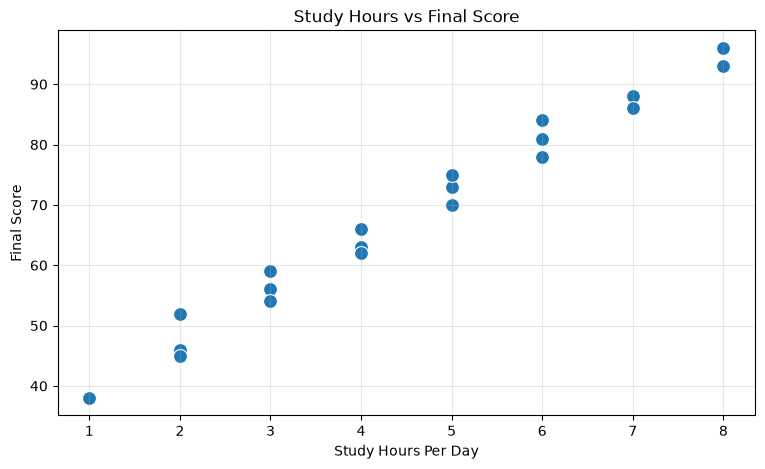

In [10]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x="Study_Hours",
    y="Final_Score",
    s=100
)

plt.title("Study Hours vs Final Score")
plt.xlabel("Study Hours Per Day")
plt.ylabel("Final Score")
plt.grid(alpha=0.3)

plt.show()


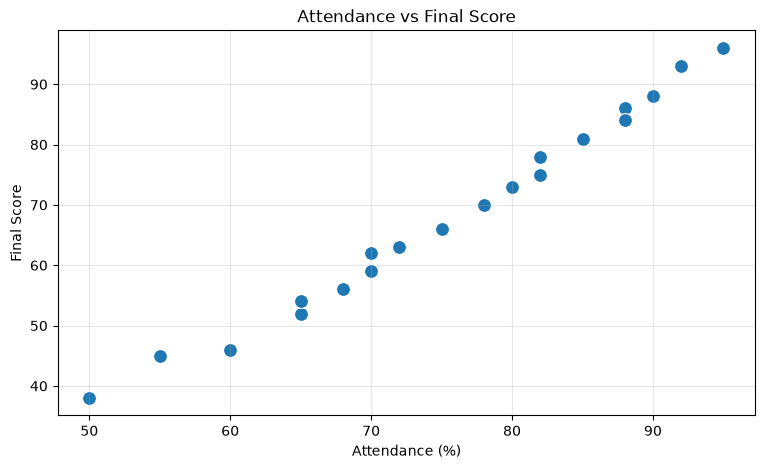

In [11]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x="Attendance",
    y="Final_Score",
    s=100
)

plt.title("Attendance vs Final Score")
plt.xlabel("Attendance (%)")
plt.ylabel("Final Score")
plt.grid(alpha=0.3)

plt.show()

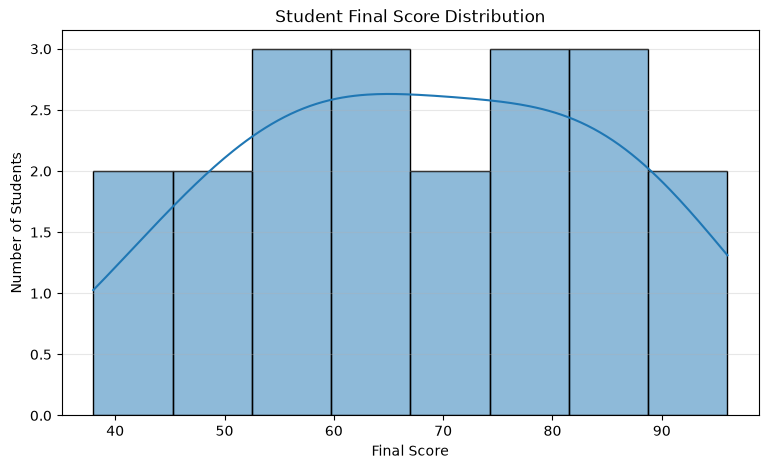

In [12]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="Final_Score",
    bins=8,
    kde=True
)

plt.title("Student Final Score Distribution")
plt.xlabel("Final Score")
plt.ylabel("Number of Students")
plt.grid(axis="y", alpha=0.3)

plt.show()

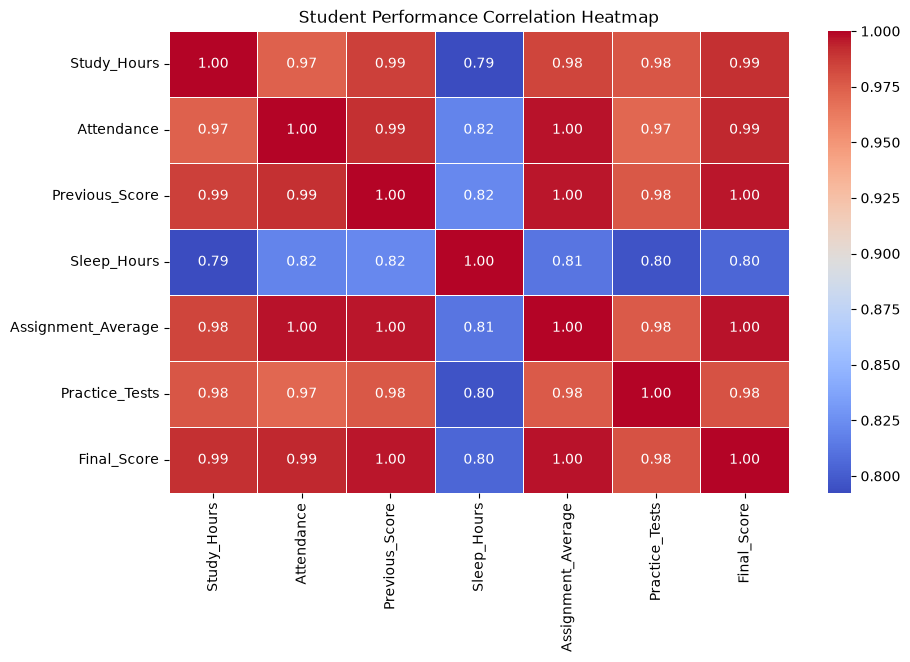

In [13]:
plt.figure(figsize=(10, 6))

correlation = df.corr(numeric_only=True)

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Student Performance Correlation Heatmap")
plt.show()

In [15]:
from sklearn.model_selection import train_test_split


X = df.drop("Final_Score", axis=1)
y = df["Final_Score"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)


Training Data: (16, 6)
Testing Data: (4, 6)


In [16]:
from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor(
    n_estimators=200,
    random_state=42
)

model.fit(X_train, y_train)

print("Model Training Completed!")

Model Training Completed!


In [17]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np


y_pred = model.predict(X_test)


mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MODEL EVALUATION RESULTS")
print("------------------------")
print("MAE:", round(mae, 2))
print("MSE:", round(mse, 2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 2))

MODEL EVALUATION RESULTS
------------------------
MAE: 1.05
MSE: 1.85
RMSE: 1.36
R2 Score: 0.96


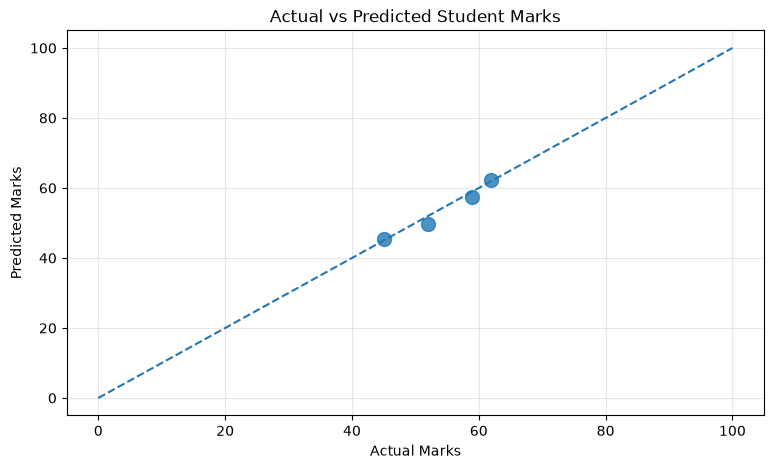

In [18]:
plt.figure(figsize=(9, 5))

plt.scatter(
    y_test,
    y_pred,
    s=100,
    alpha=0.8
)

plt.plot(
    [0, 100],
    [0, 100],
    linestyle="--"
)

plt.title("Actual vs Predicted Student Marks")
plt.xlabel("Actual Marks")
plt.ylabel("Predicted Marks")
plt.grid(alpha=0.3)

plt.show()

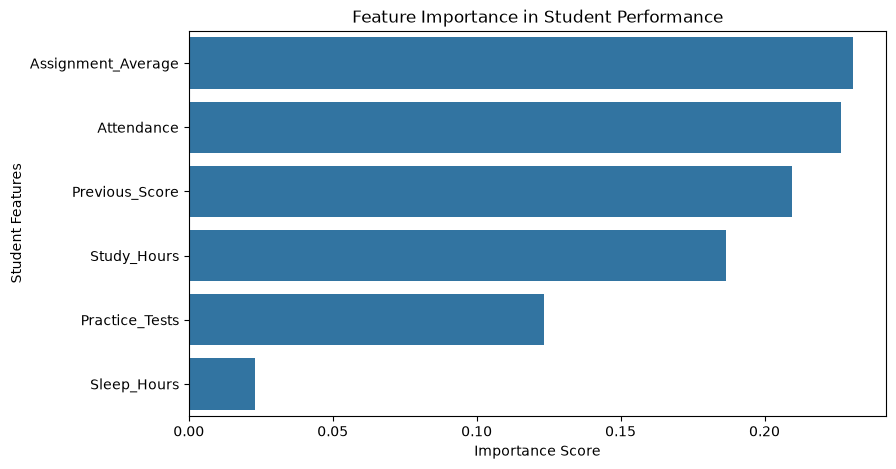

In [19]:

importance = model.feature_importances_


feature_df = pd.DataFrame({
    "Feature": X.columns,
    "Importance": importance
})


feature_df = feature_df.sort_values(
    by="Importance",
    ascending=False
)


plt.figure(figsize=(9, 5))

sns.barplot(
    data=feature_df,
    x="Importance",
    y="Feature"
)

plt.title("Feature Importance in Student Performance")
plt.xlabel("Importance Score")
plt.ylabel("Student Features")

plt.show()

In [20]:
# Create comparison DataFrame

results = pd.DataFrame({
    "Actual Marks": y_test.values,
    "Predicted Marks": np.round(y_pred, 2),
    "Prediction Error": np.round(
        np.abs(y_test.values - y_pred), 2
    )
})


results

,Actual Marks,Predicted Marks,Prediction Error
0,52,49.74,2.26
1,62,62.14,0.15
2,45,45.32,0.33
3,59,57.54,1.47


In [21]:
import joblib

joblib.dump(model, "student_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [22]:
df.to_csv("student_data_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!
